In [1]:
import pandas as pd
df = pd.read_csv("paris_listings.csv")
df.head()

,listing_id,neighbourhood,room_type,property_type,latitude,longitude,accommodates,bedrooms,beds,price,minimum_nights,availability_365,number_of_reviews,number_of_reviews_ltm,reviews_per_month,review_scores_rating,host_is_superhost,calculated_host_listings_count
0,4266398,Passy,Entire home/apt,Entire rental unit,48.85125,2.27371,2,1.0,1.0,110.37,30.0,188,3,1,0.22,5.00,False,8
1,7793559,Palais-Bourbon,Entire home/apt,Entire rental unit,48.85938,2.31105,2,1.0,1.0,241.00,1.0,328,3,0,0.11,4.33,False,65
2,8258872,Bourse,Private room,Private room in rental unit,48.86813,2.35247,7,2.0,6.0,289.75,3.0,165,266,46,2.95,4.85,True,16
3,9299834,Panthéon,Entire home/apt,Entire rental unit,48.84610,2.35203,4,2.0,3.0,323.50,1.0,70,11,9,0.80,4.82,False,1
4,9909361,Vaugirard,Entire home/apt,Entire rental unit,48.83163,2.30231,3,2.0,2.0,173.00,2.0,268,17,17,2.30,4.94,True,1


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28108 entries, 0 to 28107
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   listing_id                      28108 non-null  int64  
 1   neighbourhood                   28108 non-null  object 
 2   room_type                       28108 non-null  object 
 3   property_type                   28108 non-null  object 
 4   latitude                        28108 non-null  float64
 5   longitude                       28108 non-null  float64
 6   accommodates                    28108 non-null  int64  
 7   bedrooms                        28103 non-null  float64
 8   beds                            27175 non-null  float64
 9   price                           28108 non-null  float64
 10  minimum_nights                  28010 non-null  float64
 11  availability_365                28108 non-null  int64  
 12  number_of_reviews               

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
listing_id,28108.0,5.506014e+06,2.599772e+06,1.000358e+06,3.254932e+06,5.514730e+06,7.775756e+06,9.999630e+06
latitude,28108.0,4.886340e+01,1.695723e-02,4.881614e+01,4.885160e+01,4.886448e+01,4.887583e+01,4.890159e+01
longitude,28108.0,2.342293e+00,3.221439e-02,2.233870e+00,2.322320e+00,2.346560e+00,2.364060e+00,2.464910e+00
accommodates,28108.0,3.393233e+00,1.831312e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,1.600000e+01
bedrooms,28103.0,1.274668e+00,8.903446e-01,0.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,3.300000e+01
beds,27175.0,1.901932e+00,1.163141e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00,3.000000e+01
price,28108.0,2.716769e+02,2.007488e+02,4.000000e+01,1.420000e+02,2.140000e+02,3.326700e+02,1.500000e+03
minimum_nights,28010.0,5.752124e+00,1.848031e+01,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,3.650000e+02
availability_365,28108.0,1.922142e+02,1.188277e+02,0.000000e+00,7.700000e+01,2.120000e+02,3.060000e+02,3.650000e+02
number_of_reviews,28108.0,5.569656e+01,9.066478e+01,1.000000e+00,9.000000e+00,2.700000e+01,6.500000e+01,4.760000e+03


In [4]:
df.isna().sum()

listing_id                          0
neighbourhood                       0
room_type                           0
property_type                       0
latitude                            0
longitude                           0
accommodates                        0
bedrooms                            5
beds                              933
price                               0
minimum_nights                     98
availability_365                    0
number_of_reviews                   0
number_of_reviews_ltm               0
reviews_per_month                   0
review_scores_rating                0
host_is_superhost                   0
calculated_host_listings_count      0
dtype: int64

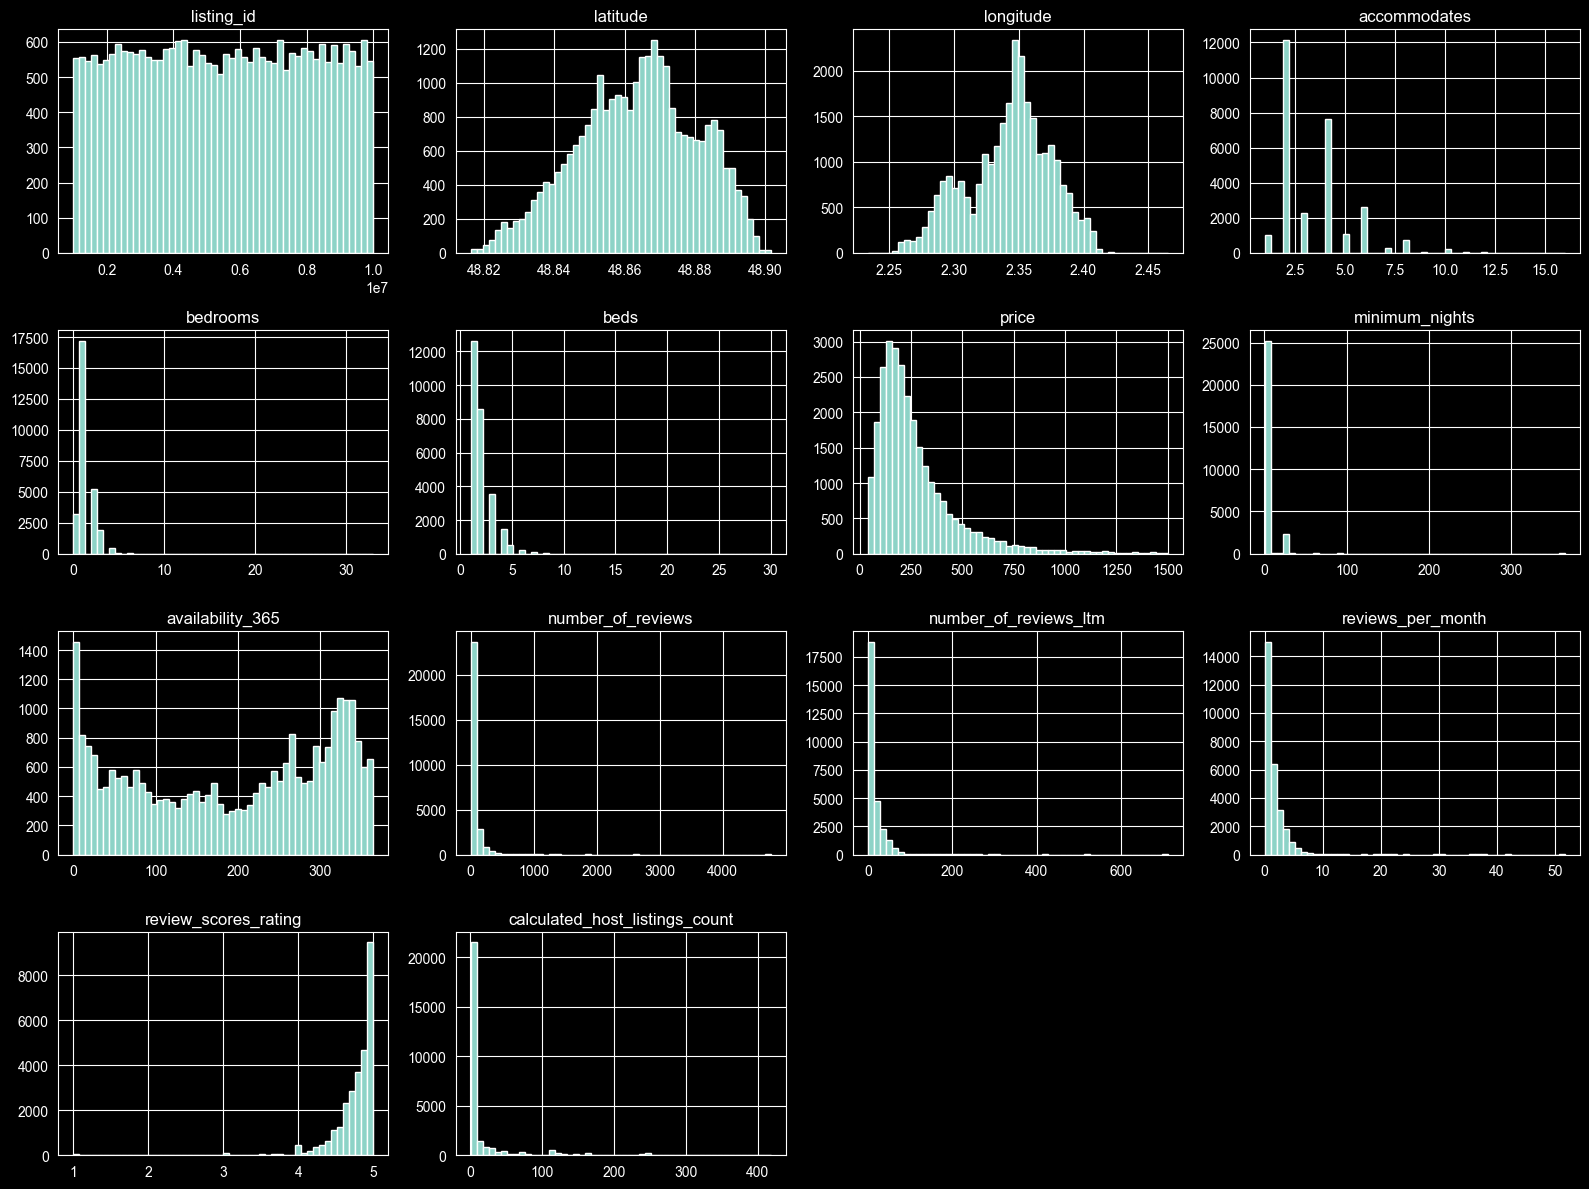

In [5]:
import matplotlib.pyplot as plt
df.hist(bins=50, figsize=(16, 12))
plt.tight_layout()
plt.show()

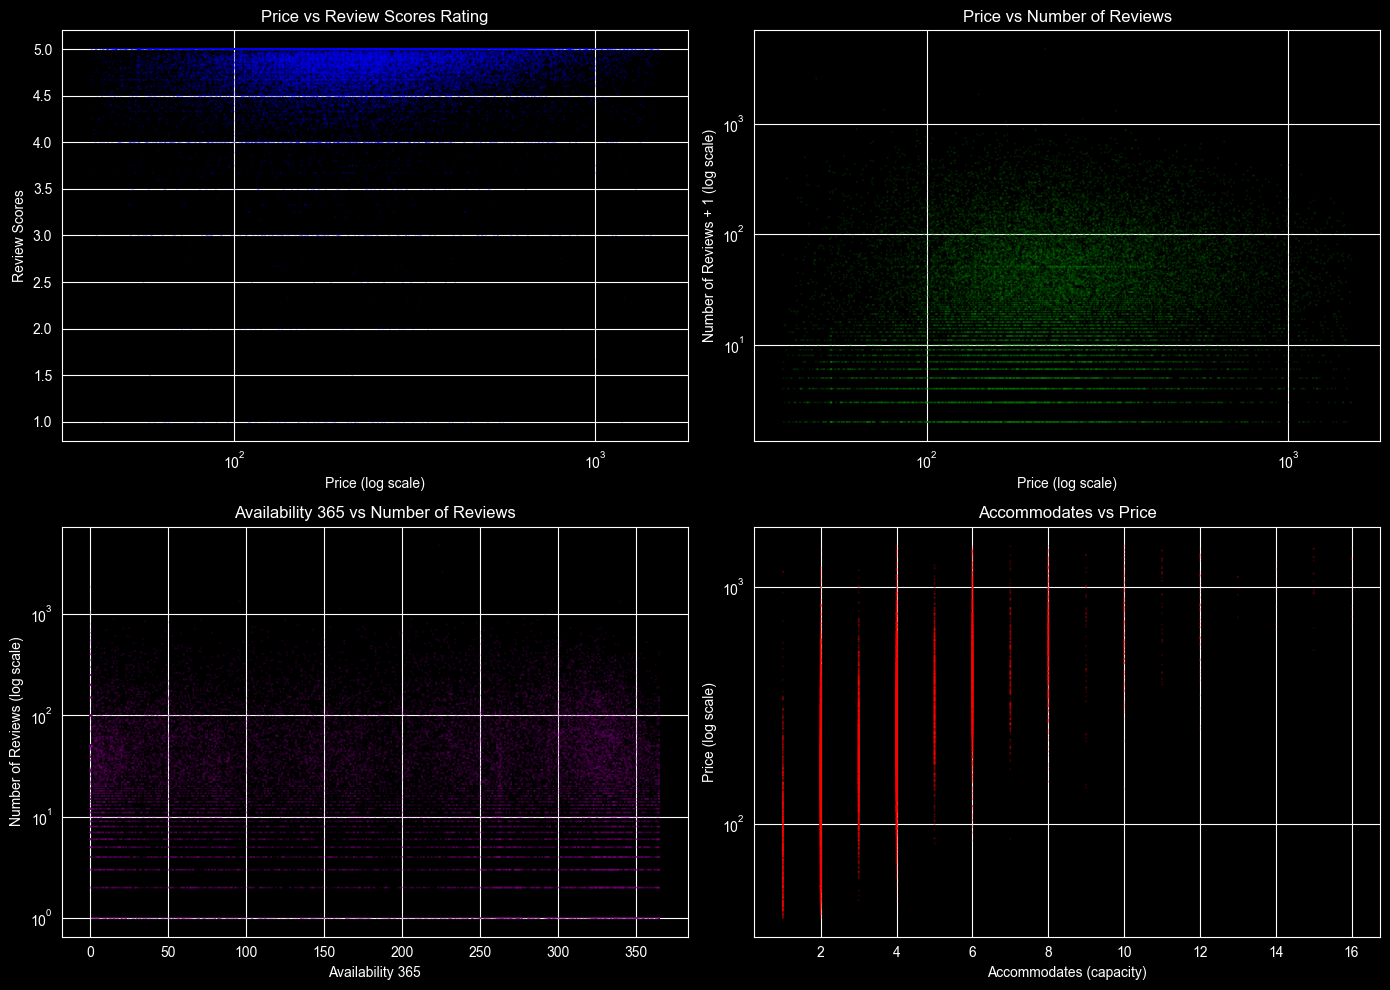

In [6]:
marker_params = {'s': 2, 'alpha': 0.2, 'edgecolors': 'none'}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# График 1: Price (логарифм) vs Review Scores Rating
axes[0, 0].scatter(df['price'], df['review_scores_rating'], color='blue', **marker_params)
axes[0, 0].set_xscale('log')
axes[0, 0].set_title('Price vs Review Scores Rating')
axes[0, 0].set_xlabel('Price (log scale)')
axes[0, 0].set_ylabel('Review Scores')

# График 2: Price (логарифм) vs Number of Reviews (логарифм)
# Чтобы избежать ошибки log(0), прибавляем 1 к отзывам
axes[0, 1].scatter(df['price'], df['number_of_reviews'] + 1, color='green', **marker_params)
axes[0, 1].set_xscale('log')
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Price vs Number of Reviews')
axes[0, 1].set_xlabel('Price (log scale)')
axes[0, 1].set_ylabel('Number of Reviews + 1 (log scale)')

# График 3: Availability 365 vs Number of Reviews
axes[1, 0].scatter(df['availability_365'], df['number_of_reviews'], color='purple', **marker_params)
axes[1, 0].set_yscale('log') # Отзывов может быть очень много у единиц, лог-шкала полезна
axes[1, 0].set_title('Availability 365 vs Number of Reviews')
axes[1, 0].set_xlabel('Availability 365')
axes[1, 0].set_ylabel('Number of Reviews (log scale)')

# График 4: Accommodates vs Price (логарифм)
axes[1, 1].scatter(df['accommodates'], df['price'], color='red', **marker_params)
axes[1, 1].set_yscale('log')
axes[1, 1].set_title('Accommodates vs Price')
axes[1, 1].set_xlabel('Accommodates (capacity)')
axes[1, 1].set_ylabel('Price (log scale)')

plt.tight_layout()
plt.show()

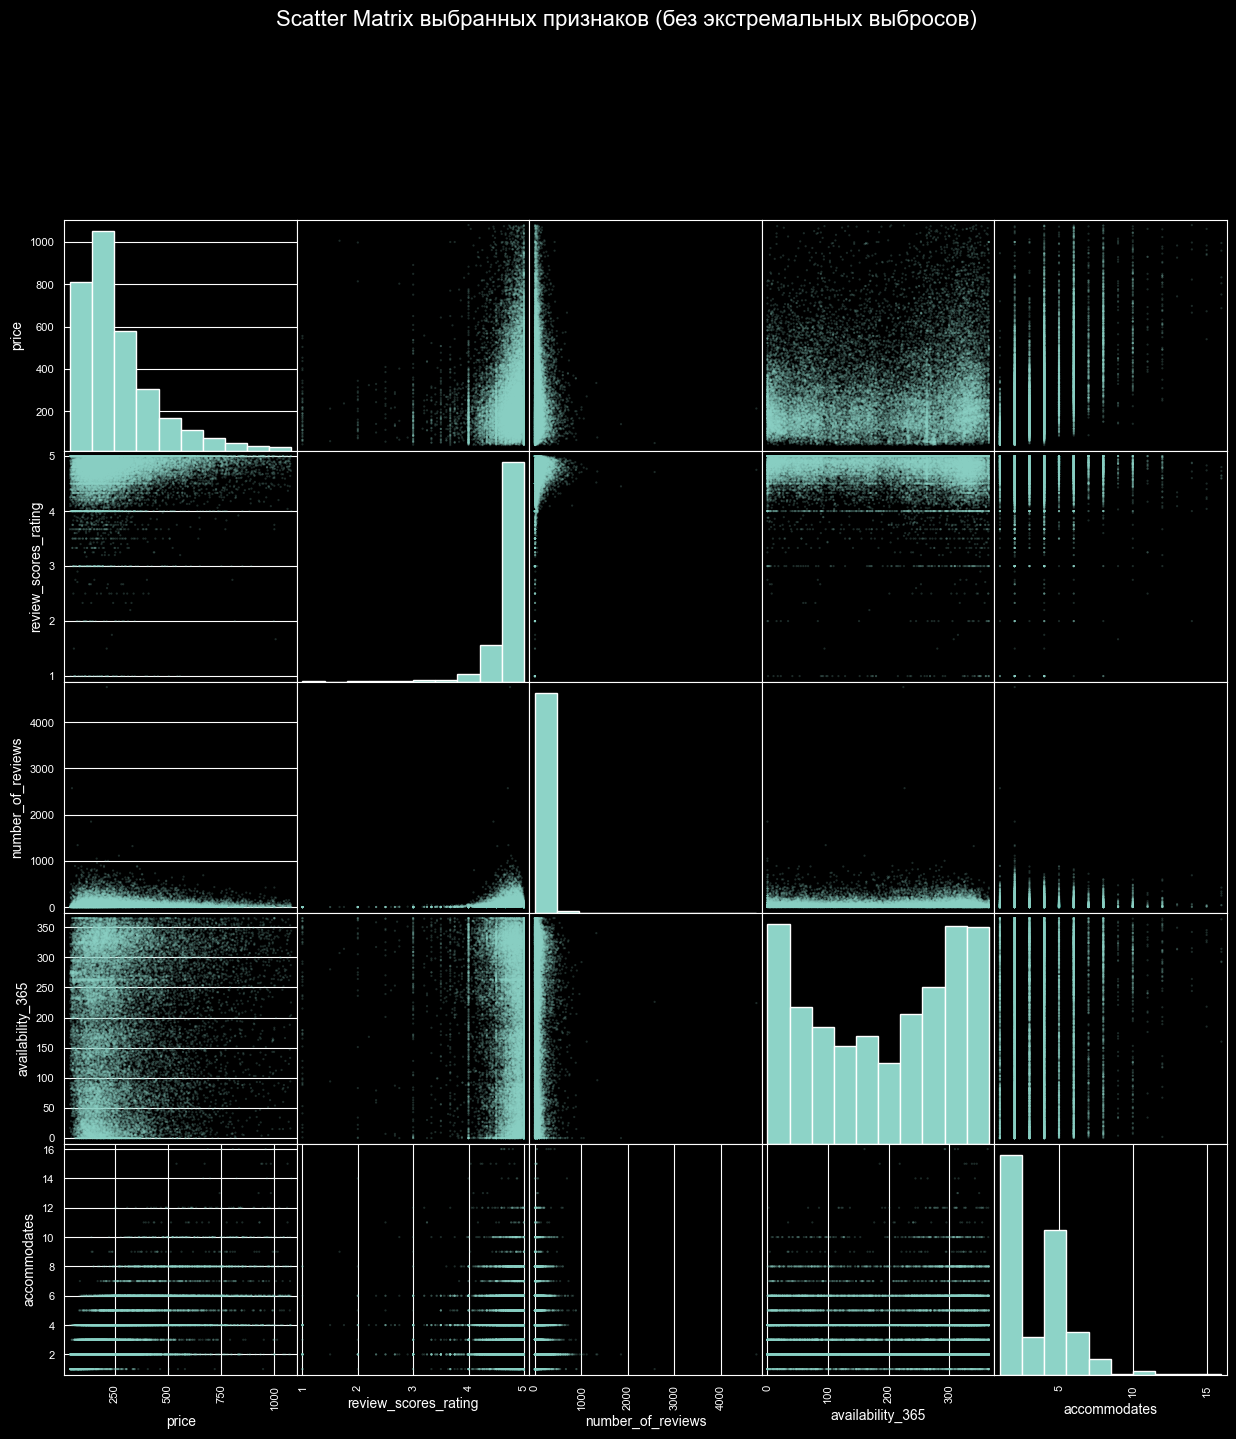

In [7]:
cols_to_plot = [
    'price',
    'review_scores_rating',
    'number_of_reviews',
    'availability_365',
    'accommodates'
]


price_cap = df['price'].quantile(0.99)
df_matrix = df[df['price'] <= price_cap].copy()

# Строим матрицу рассеяния
pd.plotting.scatter_matrix(
    df_matrix[cols_to_plot],
    alpha=0.2,
    figsize=(15, 15),
    diagonal='hist', # на диагонали будут гистограммы распределения
    marker='.',
    s=10 # для scatter_matrix размер задается немного иначе, s=10 для '.' даст нужный эффект
)

plt.suptitle('Scatter Matrix выбранных признаков (без экстремальных выбросов)', y=1.02, fontsize=16)
plt.show()

In [8]:
logical_error_mask = df["number_of_reviews_ltm"] > df["number_of_reviews"]
alien_rows_logical = df[logical_error_mask]
print(f"Строк с логической ошибкой в отзывах: {len(alien_rows_logical)}")

Строк с логической ошибкой в отзывах: 0


In [9]:
cols_to_check = ['review_scores_rating', 'reviews_per_month', 'price']

for col in cols_to_check:
    if col in df.columns:
        valid_data = df[col].dropna()
        precision_diff = (valid_data != valid_data.round(2)).sum()
        print(f"Столбец '{col}': {precision_diff} значений имеют больше двух знаков после запятой")

Столбец 'review_scores_rating': 0 значений имеют больше двух знаков после запятой
Столбец 'reviews_per_month': 0 значений имеют больше двух знаков после запятой
Столбец 'price': 0 значений имеют больше двух знаков после запятой


In [10]:
cats_to_check = ['neighbourhood', 'room_type', 'property_type', 'host_is_superhost']

for col in cats_to_check:
    print(f"\n--- Распределение в {col} ---")
    print(df[col].value_counts(dropna=False))


--- Распределение в neighbourhood ---
neighbourhood
Popincourt             2576
Buttes-Montmartre      2376
Vaugirard              2336
Entrepôt               1850
Batignolles-Monceau    1718
Temple                 1653
Opéra                  1627
Passy                  1518
Bourse                 1506
Hôtel-de-Ville         1196
Buttes-Chaumont        1163
Ménilmontant           1075
Reuilly                1062
Élysée                 1035
Panthéon                995
Luxembourg              980
Observatoire            890
Louvre                  888
Palais-Bourbon          863
Gobelins                801
Name: count, dtype: int64

--- Распределение в room_type ---
room_type
Entire home/apt    24804
Private room        3109
Hotel room           131
Shared room           64
Name: count, dtype: int64

--- Распределение в property_type ---
property_type
Entire rental unit                    23125
Private room in rental unit            1590
Room in hotel                           888
Entir

In [11]:
print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов по координатам (latitude, longitude):", df.duplicated(subset=['latitude', 'longitude']).sum())
print("Дубликатов по метрикам:", df.duplicated(subset=['price', 'review_scores_rating', 'number_of_reviews']).sum())

Полных дубликатов строк: 0
Дубликатов по координатам (latitude, longitude): 1873
Дубликатов по метрикам: 766


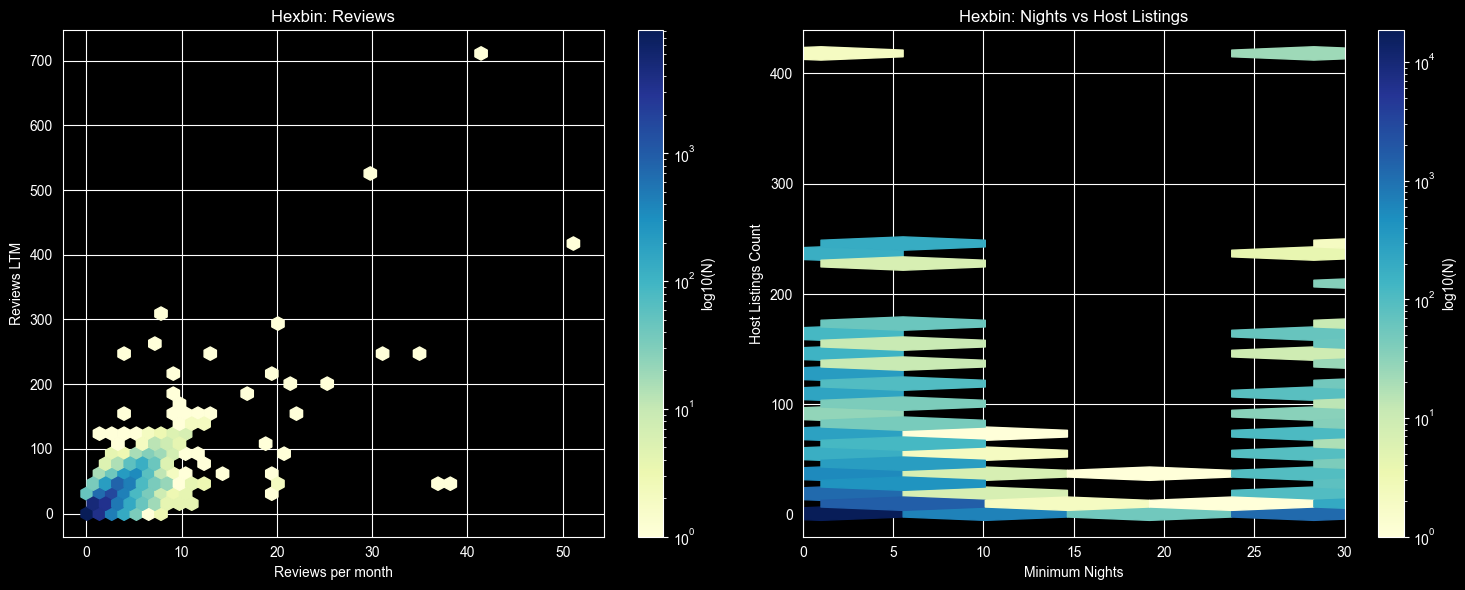

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

hb1 = axes[0].hexbin(df['reviews_per_month'], df['number_of_reviews_ltm'],
                     gridsize=40, cmap='YlGnBu', bins='log')
axes[0].set_xlabel('Reviews per month')
axes[0].set_ylabel('Reviews LTM')
axes[0].set_title('Hexbin: Reviews')
fig.colorbar(hb1, ax=axes[0], label='log10(N)')

hb2 = axes[1].hexbin(df['minimum_nights'], df['calculated_host_listings_count'],
                     gridsize=40, cmap='YlGnBu', bins='log')

axes[1].set_xlim(0, 30)
axes[1].set_xlabel('Minimum Nights')
axes[1].set_ylabel('Host Listings Count')
axes[1].set_title('Hexbin: Nights vs Host Listings')
fig.colorbar(hb2, ax=axes[1], label='log10(N)')

plt.tight_layout()
plt.show()

In [13]:
df['lat_precision'] = df['latitude'].astype(str).apply(lambda x: len(x.split('.')[1]) if '.' in x else 0)
df['lon_precision'] = df['longitude'].astype(str).apply(lambda x: len(x.split('.')[1]) if '.' in x else 0)

print("Уникальные длины хвостов latitude:\n", df['lat_precision'].value_counts())
print("\nУникальные длины хвостов longitude:\n", df['lon_precision'].value_counts())

df_sorted = df.sort_values('listing_id')
id_diff = df_sorted['listing_id'].diff()
print("\nТоп-10 частых интервалов между listing_id:\n", id_diff.value_counts().head(10))

Уникальные длины хвостов latitude:
 lat_precision
5    25212
4     2587
3      280
2       29
Name: count, dtype: int64

Уникальные длины хвостов longitude:
 lon_precision
5    25313
4     2525
3      241
2       25
1        4
Name: count, dtype: int64

Топ-10 частых интервалов между listing_id:
 listing_id
30.0    102
13.0    101
20.0    100
12.0     97
26.0     95
43.0     95
54.0     92
9.0      91
21.0     90
19.0     90
Name: count, dtype: int64


In [14]:
mask_missing = df['beds'].isna() | df['bedrooms'].isna() | df['minimum_nights'].isna()
df_missing = df[mask_missing]

print(f"Строк с целевыми пропусками: {len(df_missing)}")

if len(df_missing) > 0:
    print("\nРаспределение room_type у строк с пропусками:")
    print(df_missing['room_type'].value_counts(normalize=True).round(3))
    print("\nРаспределение review_scores_rating у строк с пропусками:")
    print(df_missing['review_scores_rating'].value_counts(dropna=False).head())

Строк с целевыми пропусками: 977

Распределение room_type у строк с пропусками:
room_type
Private room       0.536
Entire home/apt    0.448
Hotel room         0.015
Name: proportion, dtype: float64

Распределение review_scores_rating у строк с пропусками:
review_scores_rating
5.00    279
4.50     41
4.67     32
4.75     28
4.71     24
Name: count, dtype: int64


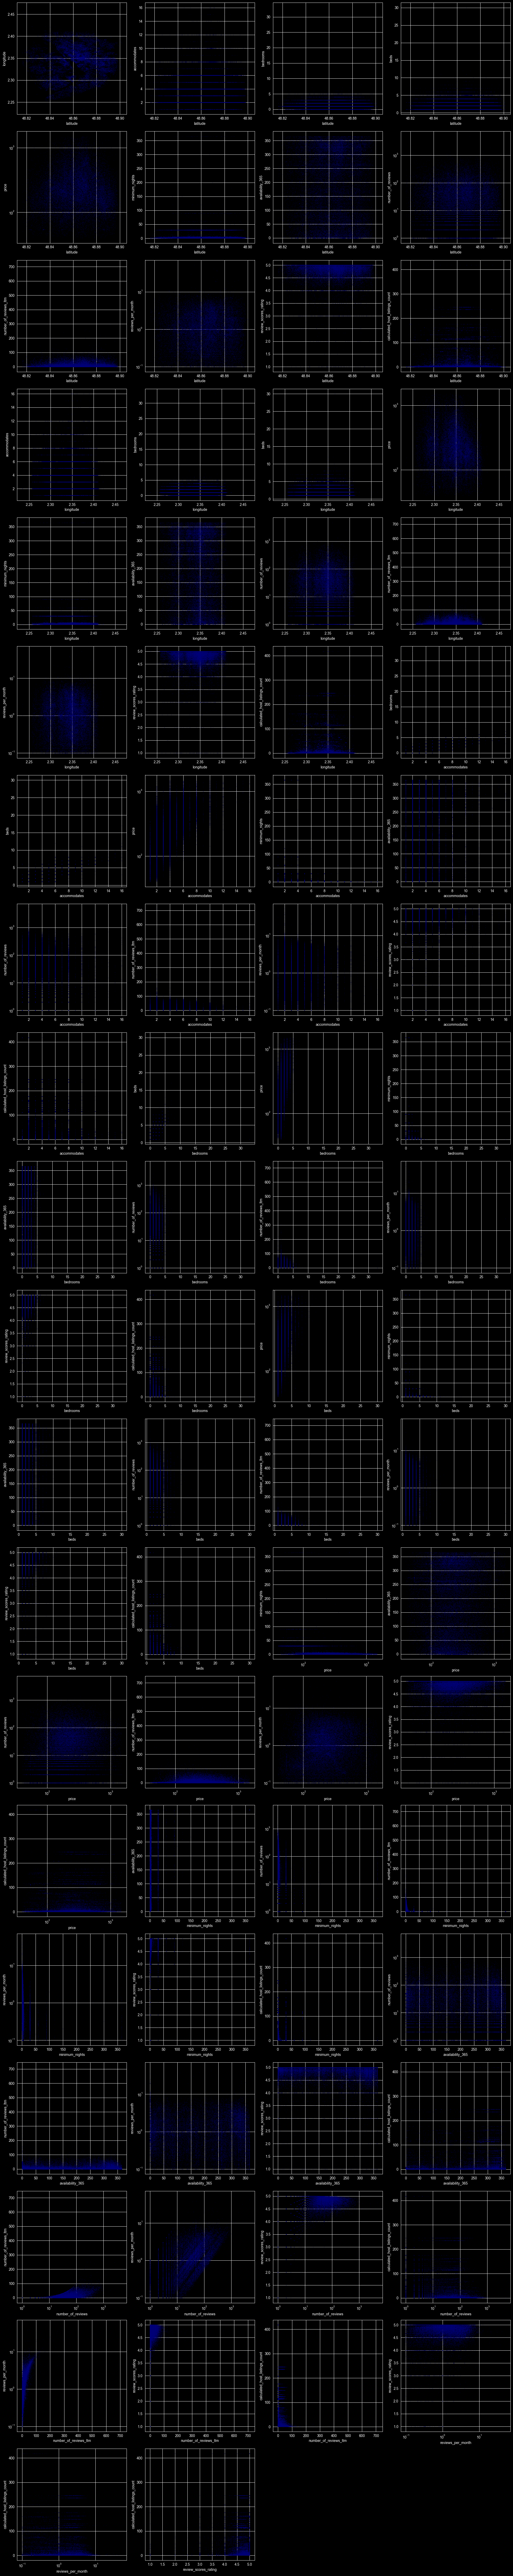

In [15]:
import itertools

num_cols = df.select_dtypes(include=['float64', 'int64']).columns.drop(
    ['listing_id', 'lat_precision', 'lon_precision'], errors='ignore'
)

pairs = list(itertools.combinations(num_cols, 2))
fig, axes = plt.subplots(len(pairs) // 4 + 1, 4, figsize=(20, 5 * (len(pairs) // 4 + 1)))
axes = axes.flatten()

for i, (col_x, col_y) in enumerate(pairs):
    axes[i].scatter(df[col_x], df[col_y], s=1, alpha=0.1, color='navy')
    axes[i].set_xlabel(col_x)
    axes[i].set_ylabel(col_y)

    # Лог-шкала для признаков с длинными хвостами
    if col_x in ['price', 'number_of_reviews', 'reviews_per_month']: axes[i].set_xscale('log')
    if col_y in ['price', 'number_of_reviews', 'reviews_per_month']: axes[i].set_yscale('log')

# Удаляем пустые подграфики, если количество пар не кратно 4
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Выделено 563 потенциальных аномалий через IsolationForest.


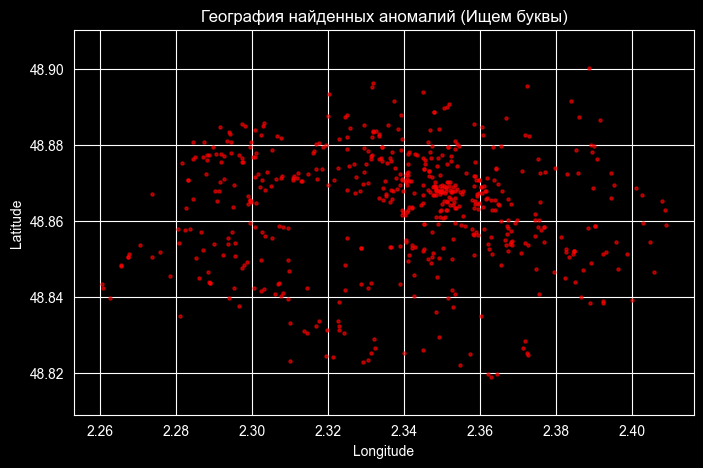

In [17]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

X = df[num_cols].fillna(df[num_cols].median())
X_scaled = StandardScaler().fit_transform(X)

iso = IsolationForest(contamination=0.02, random_state=42)
iso_labels = iso.fit_predict(X_scaled) # -1 = аномалия, 1 = норма
outliers_iso = df[iso_labels == -1]

print(f"Выделено {len(outliers_iso)} потенциальных аномалий через IsolationForest.")

if len(outliers_iso) > 0:
    plt.figure(figsize=(8, 5))
    plt.scatter(outliers_iso['longitude'], outliers_iso['latitude'], s=5, alpha=0.6, color='red')
    plt.title("География найденных аномалий (Ищем буквы)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.axis('equal')
    plt.show()

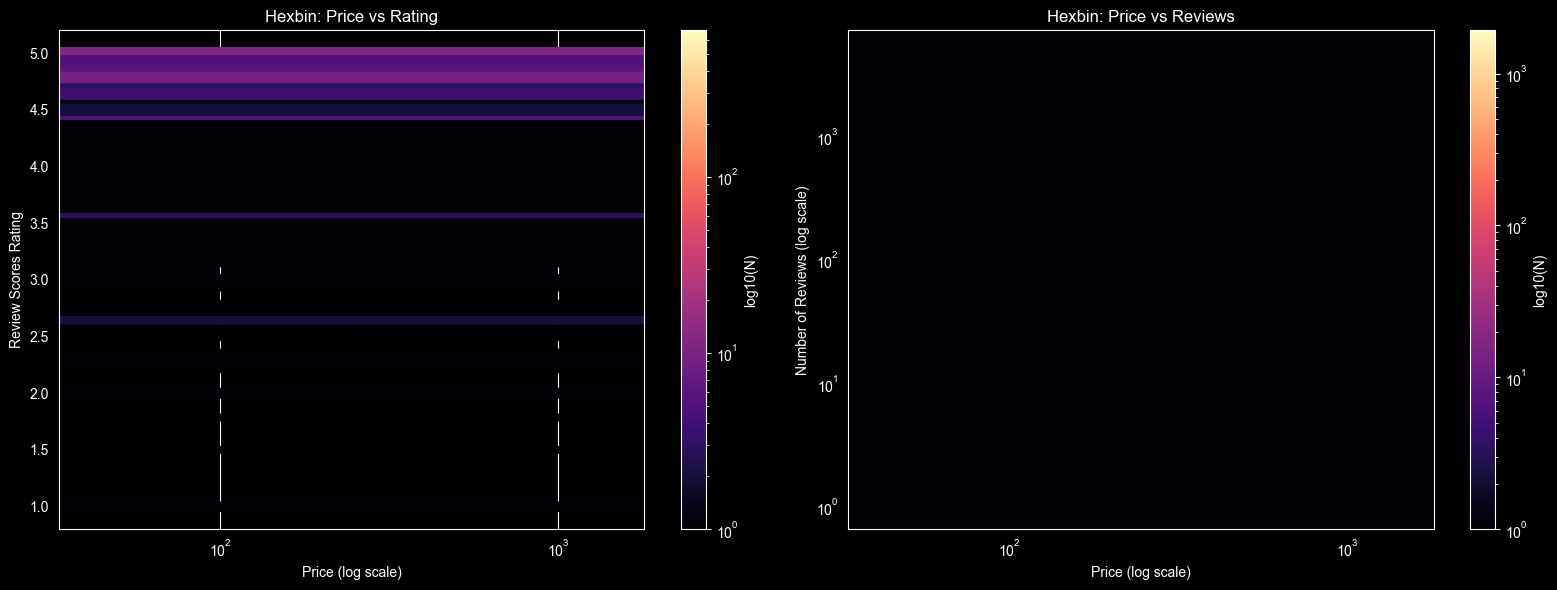

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

hb1 = axes[0].hexbin(df['price'], df['review_scores_rating'], gridsize=50, cmap='magma', bins='log')
axes[0].set_xscale('log')
axes[0].set_xlabel('Price (log scale)')
axes[0].set_ylabel('Review Scores Rating')
axes[0].set_title('Hexbin: Price vs Rating')
fig.colorbar(hb1, ax=axes[0], label='log10(N)')

hb2 = axes[1].hexbin(df['price'], df['number_of_reviews'], gridsize=50, cmap='magma', bins='log')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Price (log scale)')
axes[1].set_ylabel('Number of Reviews (log scale)')
axes[1].set_title('Hexbin: Price vs Reviews')
fig.colorbar(hb2, ax=axes[1], label='log10(N)')

plt.tight_layout()
plt.show()

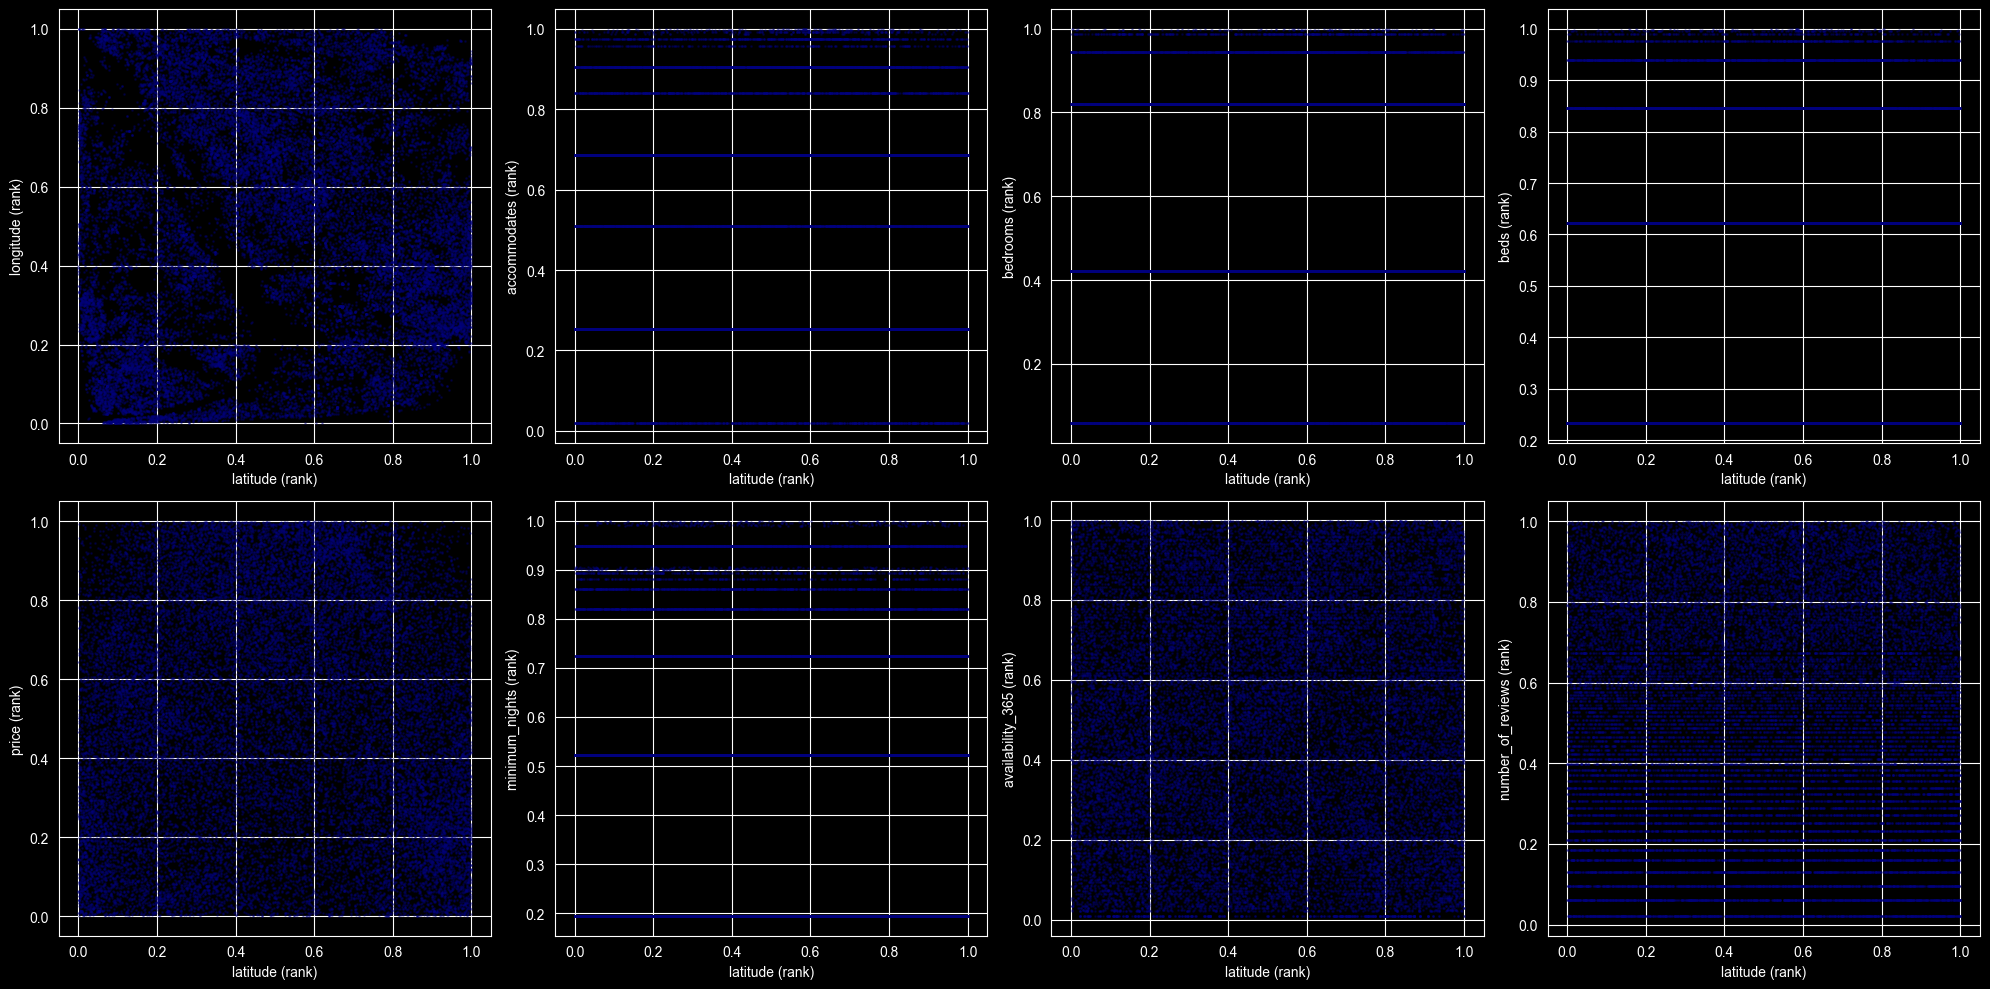

In [19]:
num_cols = df.select_dtypes(include=['float64', 'int64']).columns.drop(
    ['listing_id', 'lat_precision', 'lon_precision'], errors='ignore'
)

df_ranks = df[num_cols].rank(pct=True)

pairs = list(itertools.combinations(num_cols, 2))
chunk_size = 8

chunk_index = 0
current_pairs = pairs[chunk_index * chunk_size : (chunk_index + 1) * chunk_size]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (col_x, col_y) in enumerate(current_pairs):
    axes[i].scatter(df_ranks[col_x], df_ranks[col_y], s=1, alpha=0.3, color='navy')
    axes[i].set_xlabel(f"{col_x} (rank)")
    axes[i].set_ylabel(f"{col_y} (rank)")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Строк с пропусками: 977
Остальных строк: 27131


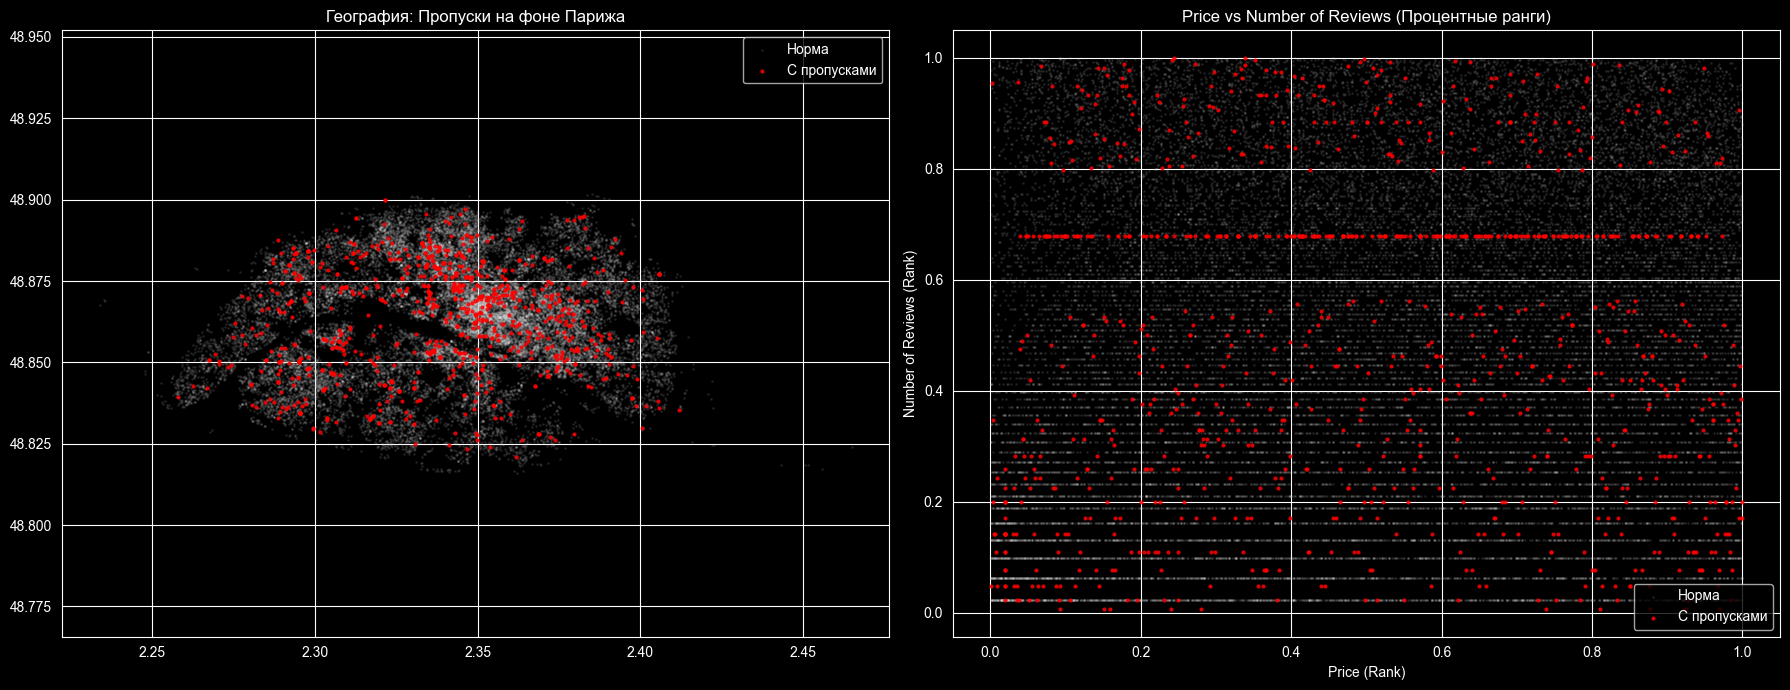

In [20]:
mask_missing = df['beds'].isna() | df['bedrooms'].isna() | df['minimum_nights'].isna() | df['review_scores_rating'].isna()
df_missing = df[mask_missing]
df_normal = df[~mask_missing]

print(f"Строк с пропусками: {len(df_missing)}")
print(f"Остальных строк: {len(df_normal)}")

if len(df_missing) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    axes[0].scatter(df_normal['longitude'], df_normal['latitude'], s=1, alpha=0.1, color='lightgray', label='Норма')
    axes[0].scatter(df_missing['longitude'], df_missing['latitude'], s=4, alpha=0.8, color='red', label='С пропусками')
    axes[0].set_title("География: Пропуски на фоне Парижа")
    axes[0].legend()
    axes[0].axis('equal')

    axes[1].scatter(df_normal['price'].rank(pct=True), df_normal['number_of_reviews'].rank(pct=True),
                    s=1, alpha=0.1, color='lightgray', label='Норма')
    axes[1].scatter(df_missing['price'].rank(pct=True), df_missing['number_of_reviews'].rank(pct=True),
                    s=4, alpha=0.8, color='red', label='С пропусками')
    axes[1].set_title("Price vs Number of Reviews (Процентные ранги)")
    axes[1].set_xlabel("Price (Rank)")
    axes[1].set_ylabel("Number of Reviews (Rank)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

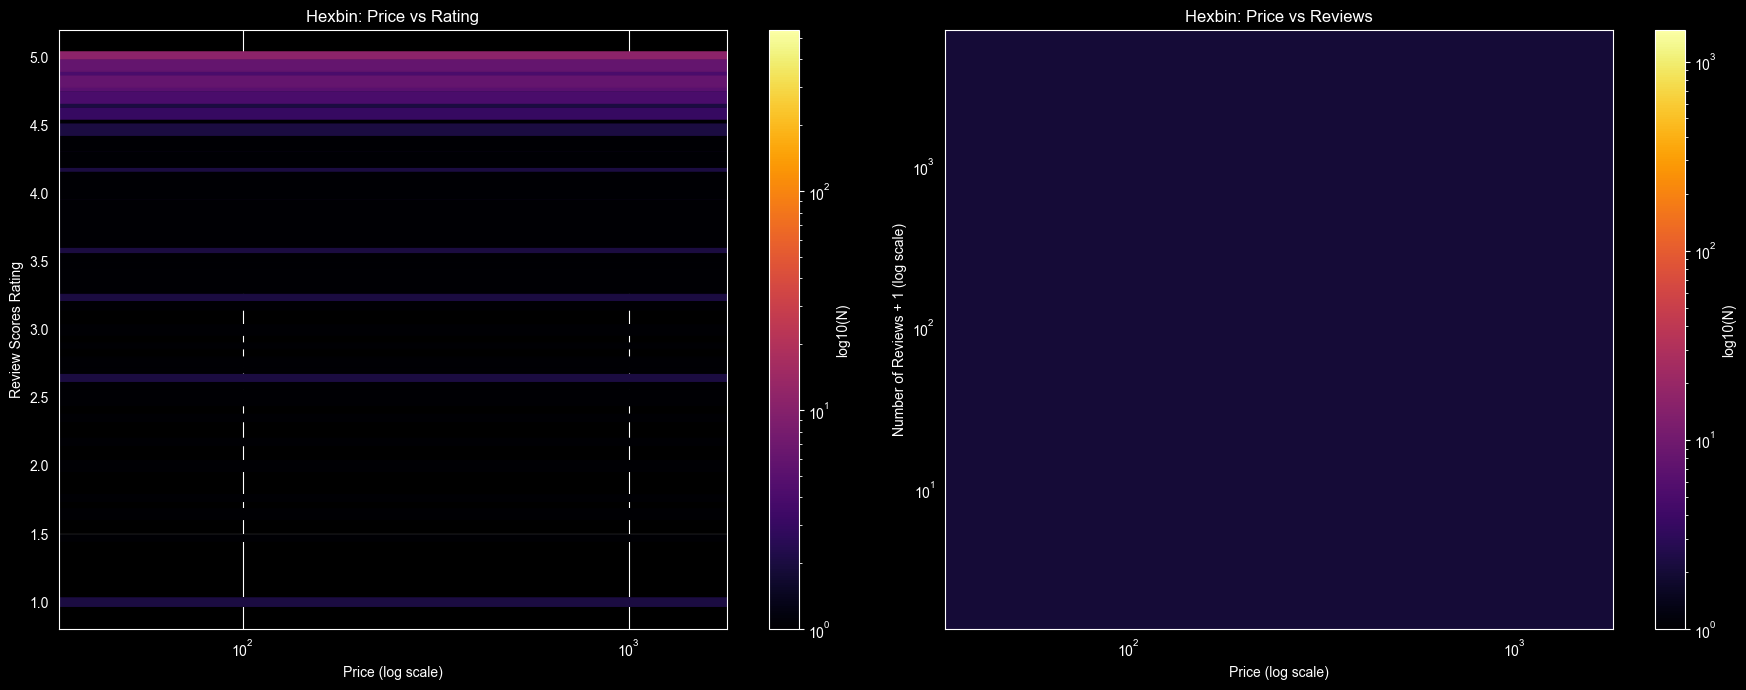

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

hb1 = axes[0].hexbin(df['price'], df['review_scores_rating'], gridsize=60, cmap='inferno', bins='log', mincnt=1)
axes[0].set_xscale('log')
axes[0].set_xlabel("Price (log scale)")
axes[0].set_ylabel("Review Scores Rating")
axes[0].set_title("Hexbin: Price vs Rating")
fig.colorbar(hb1, ax=axes[0], label='log10(N)')

hb2 = axes[1].hexbin(df['price'], df['number_of_reviews'] + 1, gridsize=60, cmap='inferno', bins='log', mincnt=1)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel("Price (log scale)")
axes[1].set_ylabel("Number of Reviews + 1 (log scale)")
axes[1].set_title("Hexbin: Price vs Reviews")
fig.colorbar(hb2, ax=axes[1], label='log10(N)')

plt.tight_layout()
plt.show()

In [22]:
import numpy as np
from sklearn.linear_model import LinearRegression

valid_reviews = df.dropna(subset=['number_of_reviews', 'reviews_per_month', 'number_of_reviews_ltm']).copy()

X_rev = valid_reviews[['number_of_reviews', 'number_of_reviews_ltm']]
y_rev = valid_reviews['reviews_per_month']

reg = LinearRegression().fit(X_rev, y_rev)
valid_reviews['predicted_rpm'] = reg.predict(X_rev)

valid_reviews['residual'] = np.abs(valid_reviews['reviews_per_month'] - valid_reviews['predicted_rpm'])

threshold = valid_reviews['residual'].quantile(0.98)
broken_reviews_df = valid_reviews[valid_reviews['residual'] > threshold]

print(f"Выделено строк с нарушенной логикой отзывов: {len(broken_reviews_df)}")

Выделено строк с нарушенной логикой отзывов: 563


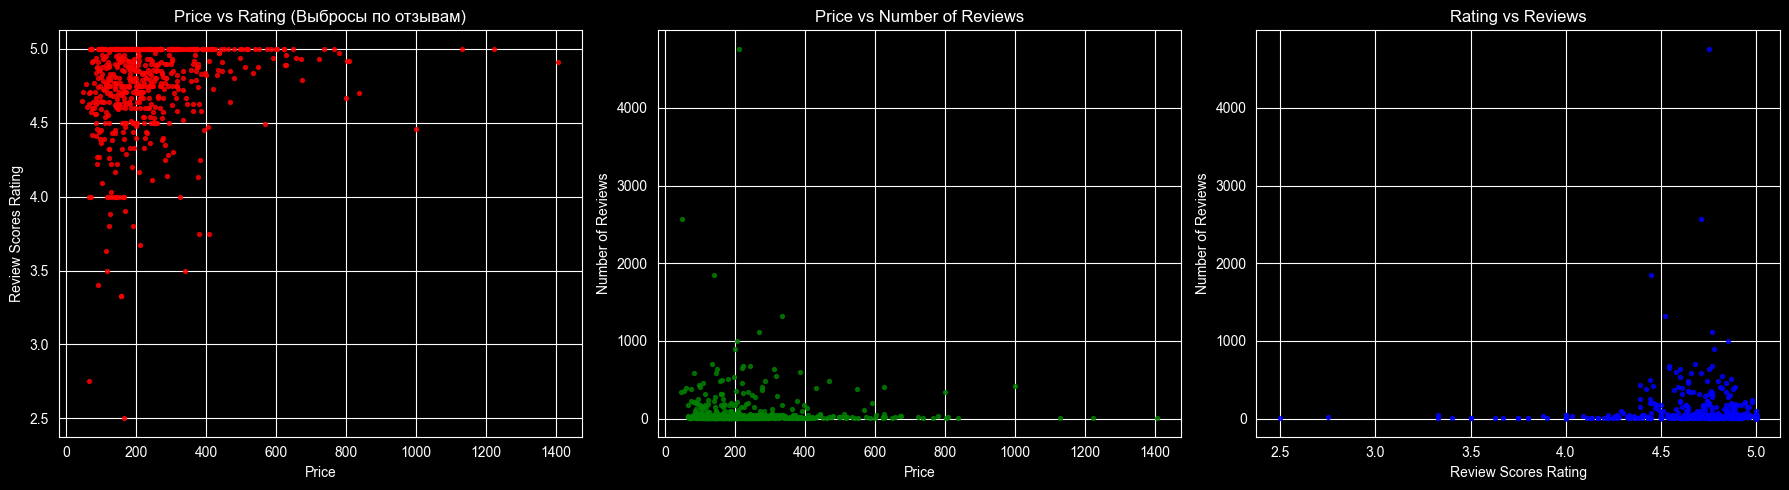

In [23]:
if len(broken_reviews_df) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Price vs Rating
    axes[0].scatter(broken_reviews_df['price'], broken_reviews_df['review_scores_rating'],
                    s=8, alpha=0.8, color='red')
    axes[0].set_title('Price vs Rating (Выбросы по отзывам)')
    axes[0].set_xlabel('Price')
    axes[0].set_ylabel('Review Scores Rating')

    # 2. Price vs Number of Reviews
    axes[1].scatter(broken_reviews_df['price'], broken_reviews_df['number_of_reviews'],
                    s=8, alpha=0.8, color='green')
    axes[1].set_title('Price vs Number of Reviews')
    axes[1].set_xlabel('Price')
    axes[1].set_ylabel('Number of Reviews')

    # 3. Rating vs Reviews
    axes[2].scatter(broken_reviews_df['review_scores_rating'], broken_reviews_df['number_of_reviews'],
                    s=8, alpha=0.8, color='blue')
    axes[2].set_title('Rating vs Reviews')
    axes[2].set_xlabel('Review Scores Rating')
    axes[2].set_ylabel('Number of Reviews')

    plt.tight_layout()
    plt.show()

Выделено строк с аномальной ценой за место: 564


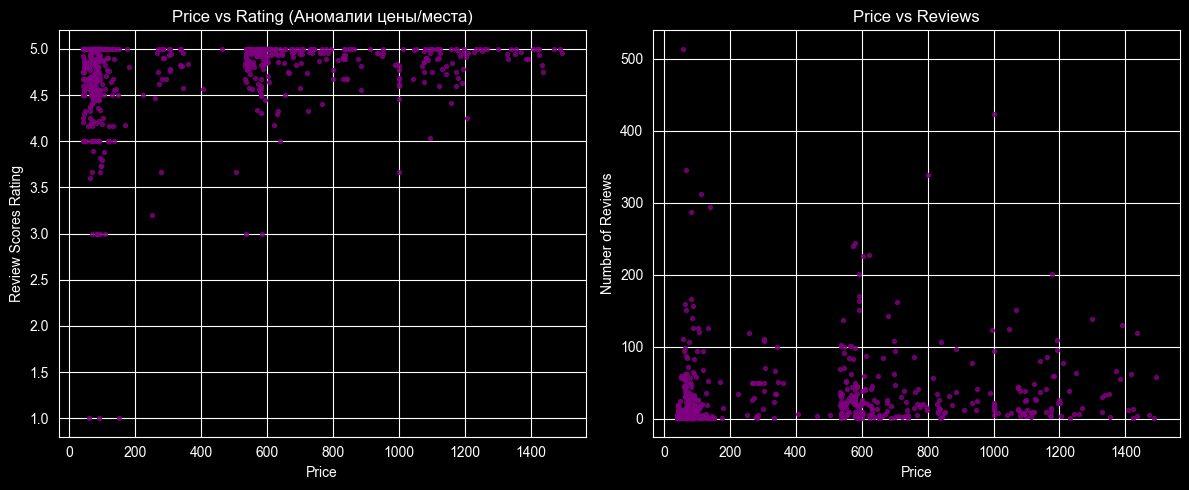

In [24]:
df['price_per_person'] = df['price'] / df['accommodates'].replace(0, 1)

ppp_lower = df['price_per_person'].quantile(0.01)
ppp_upper = df['price_per_person'].quantile(0.99)

broken_price_df = df[(df['price_per_person'] < ppp_lower) | (df['price_per_person'] > ppp_upper)]
print(f"Выделено строк с аномальной ценой за место: {len(broken_price_df)}")

if len(broken_price_df) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(broken_price_df['price'], broken_price_df['review_scores_rating'],
                    s=8, alpha=0.8, color='purple')
    axes[0].set_title('Price vs Rating (Аномалии цены/места)')
    axes[0].set_xlabel('Price')
    axes[0].set_ylabel('Review Scores Rating')

    axes[1].scatter(broken_price_df['price'], broken_price_df['number_of_reviews'],
                    s=8, alpha=0.8, color='purple')
    axes[1].set_title('Price vs Reviews')
    axes[1].set_xlabel('Price')
    axes[1].set_ylabel('Number of Reviews')

    plt.tight_layout()
    plt.show()

In [25]:
from sklearn.preprocessing import MinMaxScaler

rgb_cols = ['price', 'review_scores_rating', 'number_of_reviews']

df_norm = pd.DataFrame(index=df.index)

df_norm['price'] = df['price'].rank(pct=True)
df_norm['number_of_reviews'] = df['number_of_reviews'].rank(pct=True)

scaler = MinMaxScaler()
rating_temp = df[['review_scores_rating']].fillna(df['review_scores_rating'].median())
df_norm['review_scores_rating'] = scaler.fit_transform(rating_temp)

df_norm['grey_diff'] = df_norm[rgb_cols].max(axis=1) - df_norm[rgb_cols].min(axis=1)

print("Квантили разницы (grey_diff):")
print(df_norm['grey_diff'].quantile([0.001, 0.01, 0.05, 0.5]).round(4))

Квантили разницы (grey_diff):
0.001    0.0220
0.010    0.0691
0.050    0.1638
0.500    0.6215
Name: grey_diff, dtype: float64


Найдено идеальных 'серых' строк: 5


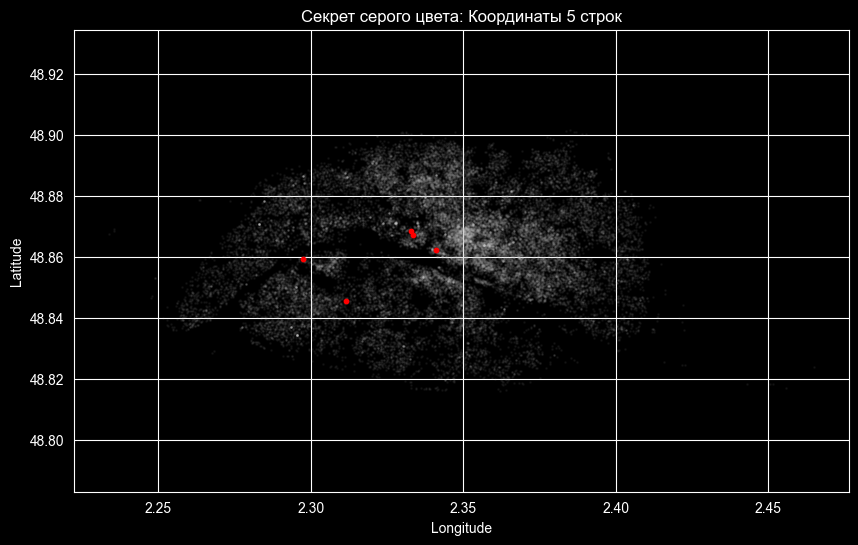

In [26]:
epsilon = 0.01
mask_grey = df_norm['grey_diff'] <= epsilon

grey_dots = df[mask_grey]
print(f"Найдено идеальных 'серых' строк: {len(grey_dots)}")

if len(grey_dots) > 0:
    plt.figure(figsize=(10, 6))

    plt.scatter(df['longitude'], df['latitude'], s=1, alpha=0.05, color='lightgray')

    plt.scatter(grey_dots['longitude'], grey_dots['latitude'], s=10, alpha=1.0, color='red')

    plt.title(f"Секрет серого цвета: Координаты {len(grey_dots)} строк")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.axis('equal')
    plt.show()
else:
    print("При таком epsilon ничего не найдено. Попробуй увеличить порог или поменять тройку признаков (rgb_cols).")

In [27]:
print("--- Рейтинг при 1 отзыве ---")
print(df[df['number_of_reviews'] == 1]['review_scores_rating'].value_counts(dropna=False).sort_index())

print("\n--- Рейтинг при 2 отзывах ---")
print(df[df['number_of_reviews'] == 2]['review_scores_rating'].value_counts(dropna=False).sort_index())

valid_1_rev_scores = [1.0, 2.0, 3.0, 4.0, 5.0]
mask_fake_ratings = (df['number_of_reviews'] == 1) & (df['review_scores_rating'].notna()) & (~df['review_scores_rating'].isin(valid_1_rev_scores))

anomalies_rating = df[mask_fake_ratings]
print(f"\nНайдено 'невозможных' строк с 1 отзывом и дробным рейтингом: {len(anomalies_rating)}")

if len(anomalies_rating) > 0:
    plt.figure(figsize=(6, 4))
    plt.scatter(anomalies_rating['longitude'], anomalies_rating['latitude'], s=10, color='red')
    plt.title("География 'невозможных' рейтингов")
    plt.axis('equal')
    plt.show()

--- Рейтинг при 1 отзыве ---
review_scores_rating
1.0     48
2.0     15
3.0     54
4.0    171
5.0    904
Name: count, dtype: int64

--- Рейтинг при 2 отзывах ---
review_scores_rating
1.0      4
1.5      2
2.0      6
2.5     10
3.0     41
3.5     35
4.0     64
4.5    152
5.0    732
Name: count, dtype: int64

Найдено 'невозможных' строк с 1 отзывом и дробным рейтингом: 0


Топ-15 самых 'старых' объявлений (в месяцах):
27018    204.761905
7187     201.538462
4080     200.000000
22920    200.000000
24342    198.870056
9741     195.683453
7569     195.321637
26168    194.736842
25404    194.444444
19937    194.117647
4318     193.750000
11905    193.243243
684      192.682927
25187    192.000000
18636    190.476190
Name: age_months, dtype: float64


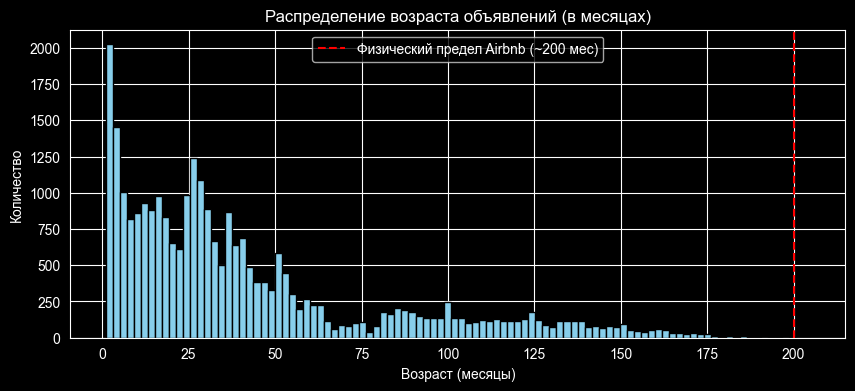


Найдено строк с аномальным возрастом: 2


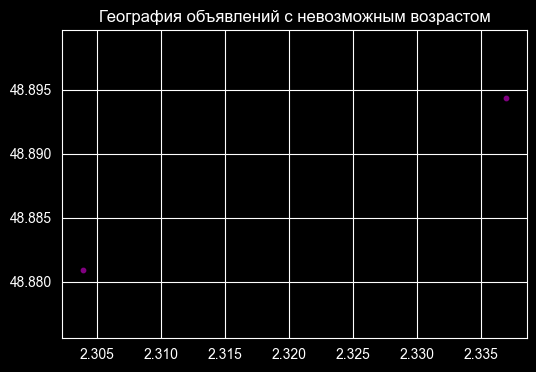

In [28]:
df['age_months'] = df['number_of_reviews'] / df['reviews_per_month'].replace(0, np.nan)

print("Топ-15 самых 'старых' объявлений (в месяцах):")
print(df['age_months'].sort_values(ascending=False).head(15))

plt.figure(figsize=(10, 4))
plt.hist(df['age_months'].dropna(), bins=100, color='skyblue', edgecolor='black')
plt.title("Распределение возраста объявлений (в месяцах)")
plt.xlabel("Возраст (месяцы)")
plt.ylabel("Количество")

plt.axvline(x=200, color='red', linestyle='--', label='Физический предел Airbnb (~200 мес)')
plt.legend()
plt.show()

mask_fake_age = (df['age_months'] > 200) | (df['age_months'] < 0)
anomalies_age = df[mask_fake_age]
print(f"\nНайдено строк с аномальным возрастом: {len(anomalies_age)}")

if len(anomalies_age) > 0:
    plt.figure(figsize=(6, 4))
    plt.scatter(anomalies_age['longitude'], anomalies_age['latitude'], s=10, color='purple')
    plt.title("География объявлений с невозможным возрастом")
    plt.axis('equal')
    plt.show()

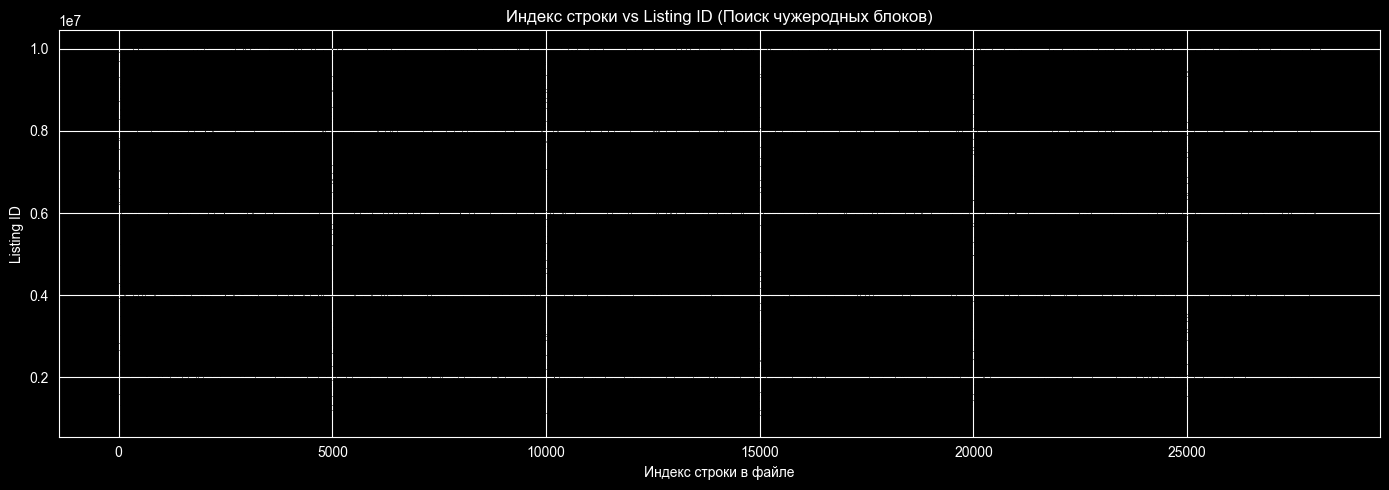

In [29]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df['listing_id'], ',', color='black', alpha=0.5)

plt.title("Индекс строки vs Listing ID (Поиск чужеродных блоков)")
plt.xlabel("Индекс строки в файле")
plt.ylabel("Listing ID")

plt.tight_layout()
plt.show()

Выделено объявлений, не совпадающих со своим районом: 141


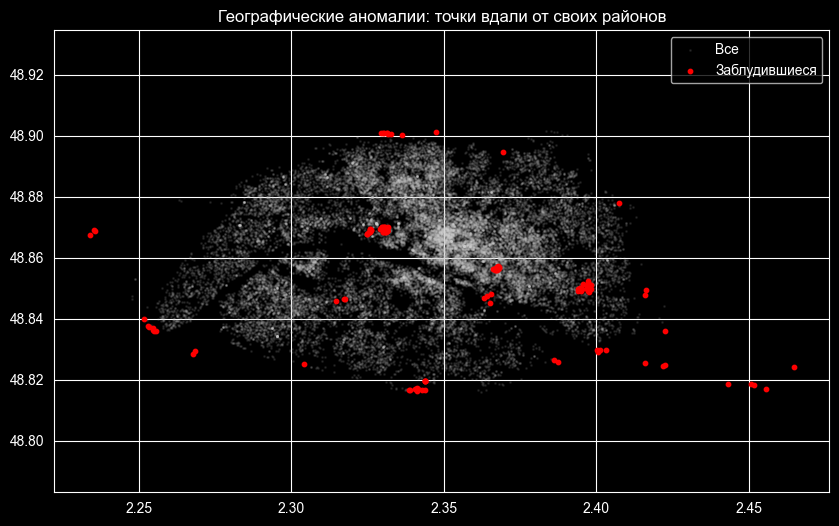

In [30]:
geo_stats = df.groupby('neighbourhood')[['latitude', 'longitude']].agg(['median', 'std'])
geo_stats.columns = ['lat_median', 'lat_std', 'lon_median', 'lon_std']

df_geo = df.join(geo_stats, on='neighbourhood')

df_geo['lat_z'] = np.abs(df_geo['latitude'] - df_geo['lat_median']) / (df_geo['lat_std'] + 1e-6)
df_geo['lon_z'] = np.abs(df_geo['longitude'] - df_geo['lon_median']) / (df_geo['lon_std'] + 1e-6)

df_geo['geo_outlier_score'] = df_geo['lat_z']**2 + df_geo['lon_z']**2

threshold = df_geo['geo_outlier_score'].quantile(0.995)
lost_points = df_geo[df_geo['geo_outlier_score'] > threshold]

print(f"Выделено объявлений, не совпадающих со своим районом: {len(lost_points)}")

if len(lost_points) > 0:
    plt.figure(figsize=(10, 6))
    plt.scatter(df['longitude'], df['latitude'], s=1, alpha=0.1, color='lightgray', label='Все')
    plt.scatter(lost_points['longitude'], lost_points['latitude'], s=10, color='red', label='Заблудившиеся')
    plt.title("Географические аномалии: точки вдали от своих районов")
    plt.legend()
    plt.axis('equal')
    plt.show()

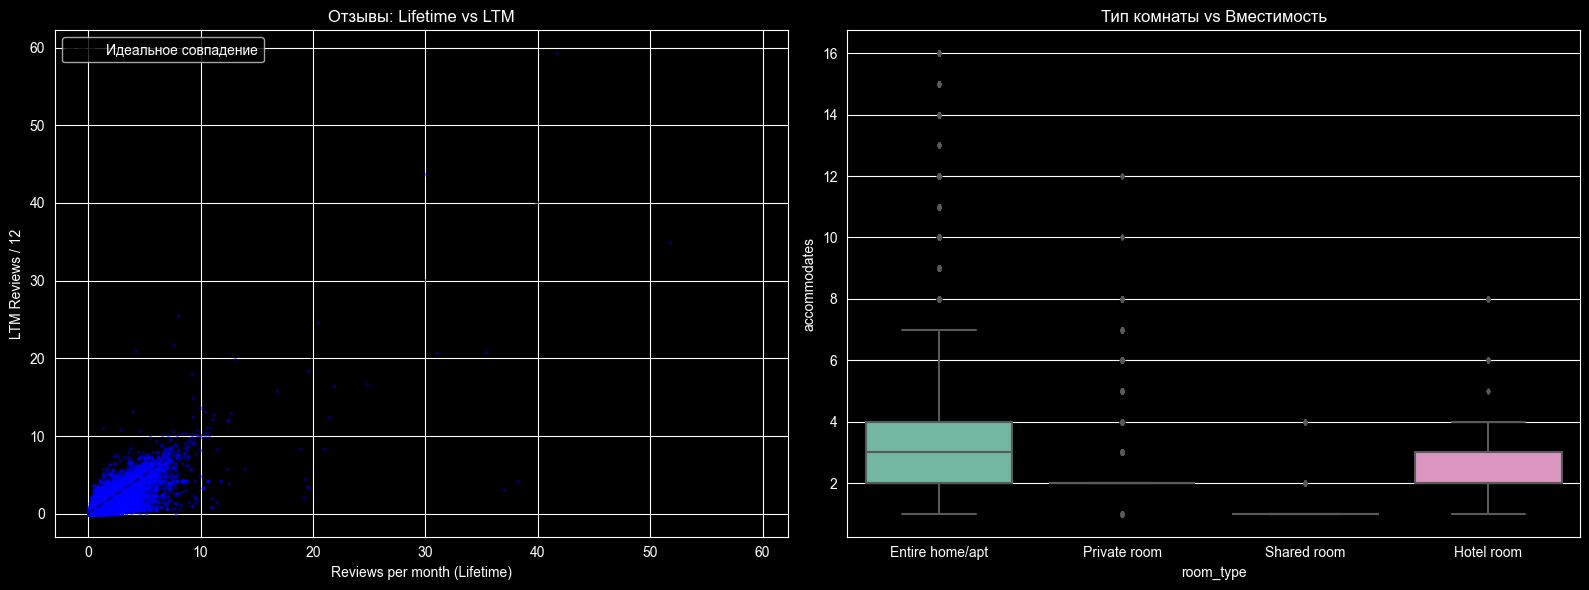


Найдено комнат с неадекватной вместимостью: 2
Найдено невозможных суперхостов: 0


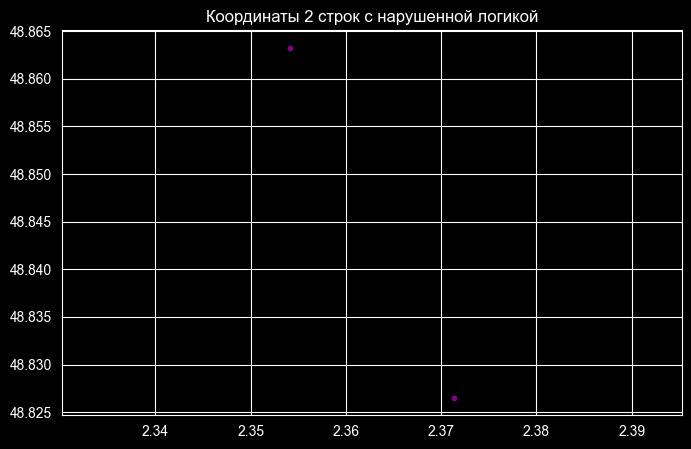

In [31]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df['ltm_monthly_avg'] = df['number_of_reviews_ltm'] / 12
axes[0].scatter(df['reviews_per_month'], df['ltm_monthly_avg'], s=3, alpha=0.3, color='blue')
axes[0].set_xlabel('Reviews per month (Lifetime)')
axes[0].set_ylabel('LTM Reviews / 12')
axes[0].set_title('Отзывы: Lifetime vs LTM')

max_val = df[['reviews_per_month', 'ltm_monthly_avg']].max().max()
axes[0].plot([0, max_val], [0, max_val], 'k--', alpha=0.5, label='Идеальное совпадение')
axes[0].legend()

sns.boxplot(data=df, x='room_type', y='accommodates', ax=axes[1], fliersize=3, palette='Set2')
axes[1].set_title('Тип комнаты vs Вместимость')

plt.tight_layout()
plt.show()

fake_capacity = df[((df['room_type'] == 'Private room') & (df['accommodates'] > 8)) |
                   ((df['room_type'] == 'Shared room') & (df['accommodates'] > 6))]

fake_hosts = df[(df['host_is_superhost'] == 't') & (df['number_of_reviews'] == 0)]

print(f"\nНайдено комнат с неадекватной вместимостью: {len(fake_capacity)}")
print(f"Найдено невозможных суперхостов: {len(fake_hosts)}")

# Отрисовка
anomalies_logic = pd.concat([fake_capacity, fake_hosts]).drop_duplicates()
if len(anomalies_logic) > 0:
    plt.figure(figsize=(8, 5))
    plt.scatter(anomalies_logic['longitude'], anomalies_logic['latitude'], s=10, color='purple')
    plt.title(f"Координаты {len(anomalies_logic)} строк с нарушенной логикой")
    plt.axis('equal')
    plt.show()